<a href="https://colab.research.google.com/github/gezahagnhailegnaw71-a11y/numerical_practice/blob/main/False_Position_Method_Final_(2).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# False Position Method (Regula Falsi)
**Numerical Analysis · Lab · Final version**

**Problem.** Solve $f(x)=0$ on an interval $[a,b]$.

**Idea.** Like bisection, but instead of the midpoint we use the point where the **straight line (chord)** through $(a,f(a))$ and $(b,f(b))$ crosses the $x$-axis:

$$c = b - \frac{f(b)\,(b-a)}{f(b)-f(a)}$$

Then keep the part with the sign change: if $f(a)f(c)<0$ set $b=c$, otherwise set $a=c$.

## Step 1: Import

In [ ]:
import math

## Step 2: Notation (quick reminder)
The **full notation guide** (math symbols in Python, the three meanings of `f`, all format codes, how to build a table) is in the notebook **Bisection_Method_Final.ipynb**. Here is only a short reminder, and the notation that is **new** in false position.

| Format code | Meaning | Example |
|---|---|---|
| `f"{x:>12.6f}"` | right aligned, width 12, 6 decimals | `    3.141593` |
| `f"{x:>12.2e}"` | scientific notation | `    3.14e+00` |
| `f"{n:>5d}"` | whole number, width 5 | `    7` |

Table = **header**, **line** `"-" * 57`, one **row** for each step.

### New in false position
| Notation | Meaning |
|---|---|
| `c_old` | the **previous** value of `c` (to compare with the new one) |
| `abs(c - c_old) < tol` | $\lvert c - c_{old}\rvert < \text{tol}$: two answers are almost the same, so **stop** |
| `break` | leave the loop immediately |
| `for step in range(1, 1000)` | at most 999 steps (a safety limit, we normally stop earlier with `break`) |
| `b - f(b) * (b - a) / (f(b) - f(a))` | the chord formula. **Brackets matter:** `(b - a) / (f(b) - f(a))` is correct, `b - a / f(b) - f(a)` is **wrong** |

Let us compute **one** chord step by hand with the formula $c = b - \dfrac{f(b)\,(b-a)}{f(b)-f(a)}$:

In [ ]:
def f(x):
    return x**3 + 4*x**2 - 10

a, b = 1, 2
print("f(a) =", f(a), "  f(b) =", f(b))

top    = f(b) * (b - a)             # numerator:   f(b)(b - a)
bottom = f(b) - f(a)                # denominator: f(b) - f(a)
c = b - top / bottom                # the chord formula
print("c =", c, "  f(c) =", f(c))

midpoint = (a + b) / 2              # compare: bisection would use the midpoint
print("bisection would use c =", midpoint)

f(a) = -5   f(b) = 14
c = 1.263157894736842   f(c) = -1.602274384020994
bisection would use c = 1.5


## Step 3: Write the functions
### 3a. `print_table`: prints the steps as a table
We write the printing **once**, so every version of the method can use it.

In [ ]:
COLUMNS = ["step", "a", "b", "c", "f(c)"]

def print_table(table):
    # header, line, one row for each step, line
    print(f"{'step':>5} {'a':>12} {'b':>12} {'c':>12} {'f(c)':>12}")
    print("-" * 57)
    for row in table:
        print(f"{row[0]:>5d} {row[1]:>12.6f} {row[2]:>12.6f} {row[3]:>12.6f} {row[4]:>12.2e}")
    print("-" * 57)

### 3b. `false_position` with a `for` loop
The loop runs at most `max_iter` times and stops early with `break` when two answers are almost the same.

In [ ]:
def false_position(f, a, b, tol=0.0001, max_iter=1000, show=True):
    # f       : the function we want to solve, f(x) = 0
    # a, b    : the interval [a, b]
    # tol     : stop when two answers differ by less than tol
    # max_iter: safety limit on the number of steps
    # show    : True = print the table

    # check the sign change
    if f(a) * f(b) > 0:
        print("Error: f(a) and f(b) must have opposite signs")
        return None, []

    table = []                                    # we store one row for each step
    c_old = a
    for step in range(1, max_iter + 1):           # at most max_iter steps
        c = b - f(b) * (b - a) / (f(b) - f(a))    # where the chord crosses the x-axis
        table.append([step, a, b, c, f(c)])       # save this row

        if f(c) == 0 or abs(c - c_old) < tol:     # exact root, or two answers almost the same: stop
            break

        if f(a) * f(c) < 0:                       # root in [a, c]
            b = c
        else:                                     # root in [c, b]
            a = c
        c_old = c

    if show:
        print_table(table)
        print("Root =", c, "  (found in", step, "steps)\n")

    return c, table

## Step 4: Solve Example 1
$x^3+4x^2-10=0$ on $[1,2]$

Look at the column `b`: it never changes. This is typical for false position.

In [ ]:
def f1(x):
    return x**3 + 4*x**2 - 10

root, table = false_position(f1, 1, 2)

 step            a            b            c         f(c)
---------------------------------------------------------
    1     1.000000     2.000000     1.263158    -1.60e+00
    2     1.263158     2.000000     1.338828    -4.30e-01
    3     1.338828     2.000000     1.358546    -1.10e-01
    4     1.358546     2.000000     1.363547    -2.78e-02
    5     1.363547     2.000000     1.364807    -6.98e-03
    6     1.364807     2.000000     1.365124    -1.76e-03
    7     1.365124     2.000000     1.365203    -4.41e-04
---------------------------------------------------------
Root = 1.3652033036626001   (found in 7 steps)



## Step 5: Solve more examples
We only change the function and the interval, then call `false_position` again.

In [ ]:
# Example 2:  cos(x) - x = 0  on [0, 1]
def f2(x):
    return math.cos(x) - x

root, table = false_position(f2, 0, 1)

 step            a            b            c         f(c)
---------------------------------------------------------
    1     0.000000     1.000000     0.685073     8.93e-02
    2     0.685073     1.000000     0.736299     4.66e-03
    3     0.736299     1.000000     0.738945     2.34e-04
    4     0.738945     1.000000     0.739078     1.17e-05
    5     0.739078     1.000000     0.739085     5.87e-07
---------------------------------------------------------
Root = 0.7390847824489231   (found in 5 steps)



In [ ]:
# Example 3:  x^2 - 2 = 0  on [1, 2]   (the answer is the square root of 2)
def f3(x):
    return x**2 - 2

root, table = false_position(f3, 1, 2)

 step            a            b            c         f(c)
---------------------------------------------------------
    1     1.000000     2.000000     1.333333    -2.22e-01
    2     1.333333     2.000000     1.400000    -4.00e-02
    3     1.400000     2.000000     1.411765    -6.92e-03
    4     1.411765     2.000000     1.413793    -1.19e-03
    5     1.413793     2.000000     1.414141    -2.04e-04
    6     1.414141     2.000000     1.414201    -3.50e-05
---------------------------------------------------------
Root = 1.4142011834319526   (found in 6 steps)



In [ ]:
# Example 4:  x^3 - x - 2 = 0  on [1, 2]
def f4(x):
    return x**3 - x - 2

root, table = false_position(f4, 1, 2)

 step            a            b            c         f(c)
---------------------------------------------------------
    1     1.000000     2.000000     1.333333    -9.63e-01
    2     1.333333     2.000000     1.462687    -3.33e-01
    3     1.462687     2.000000     1.504019    -1.02e-01
    4     1.504019     2.000000     1.516331    -2.99e-02
    5     1.516331     2.000000     1.519919    -8.68e-03
    6     1.519919     2.000000     1.520957    -2.51e-03
    7     1.520957     2.000000     1.521258    -7.25e-04
    8     1.521258     2.000000     1.521344    -2.09e-04
---------------------------------------------------------
Root = 1.521344484231523   (found in 8 steps)



In [ ]:
# Example 5:  e^x - 3x = 0  on [0, 1]
def f5(x):
    return math.exp(x) - 3*x

root, table = false_position(f5, 0, 1)

 step            a            b            c         f(c)
---------------------------------------------------------
    1     0.000000     1.000000     0.780203    -1.59e-01
    2     0.000000     0.780203     0.673347    -5.93e-02
    3     0.000000     0.673347     0.635682    -1.87e-02
    4     0.000000     0.635682     0.623991    -5.61e-03
    5     0.000000     0.623991     0.620509    -1.65e-03
    6     0.000000     0.620509     0.619485    -4.84e-04
    7     0.000000     0.619485     0.619185    -1.42e-04
    8     0.000000     0.619185     0.619098    -4.15e-05
---------------------------------------------------------
Root = 0.6190975876088946   (found in 8 steps)



In [ ]:
# Example 6:  a wrong interval (no sign change)
false_position(f1, 2, 3)

Error: f(a) and f(b) must have opposite signs


(None, [])

## Step 6 (optional): The same table with pandas
The function also **returns** the table (a list of rows). With `pandas` we can turn it into a nice table in one line.

In [ ]:
import pandas as pd

root, table = false_position(f1, 1, 2, show=False)      # show=False: do not print, just return the rows
df = pd.DataFrame(table, columns=COLUMNS)
df

,step,a,b,c,f(c)
0,1,1.000000,2,1.263158,-1.602274
1,2,1.263158,2,1.338828,-0.430365
2,3,1.338828,2,1.358546,-0.110009
3,4,1.358546,2,1.363547,-0.027762
4,5,1.363547,2,1.364807,-0.006983
5,6,1.364807,2,1.365124,-0.001755
6,7,1.365124,2,1.365203,-0.000441


## Step 7 (optional): Plot the error at each step

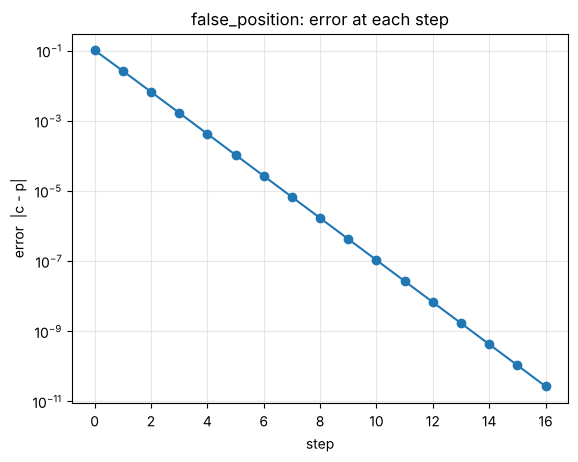

In [ ]:
import matplotlib.pyplot as plt

p = 1.365230013414097                           # the true root of f1
root, table = false_position(f1, 1, 2, tol=1e-10, show=False)

errors = [abs(row[3] - p) for row in table]     # error |c - p| at each step
plt.semilogy(errors, "o-")                      # log scale on the y-axis
plt.xlabel("step"); plt.ylabel("error  |c - p|"); plt.grid(alpha=0.3)
plt.title("false_position: error at each step"); plt.show()

## Step 8: The same method with a `while` loop
A `for` loop runs at most `max_iter` times and leaves early with `break`.
A `while` loop repeats **while** a condition is true. Here: while the two last answers are still far apart **and** we have not reached `max_iter`.

To start the loop we set `diff = tol + 1` (a number bigger than `tol`), so the condition is true the first time.

In [ ]:
def false_position_while(f, a, b, tol=0.0001, max_iter=1000, show=True):
    # same inputs and outputs as false_position, but written with a while loop

    # check the sign change
    if f(a) * f(b) > 0:
        print("Error: f(a) and f(b) must have opposite signs")
        return None, []

    table = []                                    # one row for each step
    step = 0
    c_old = a
    diff = tol + 1                                # bigger than tol, so the loop starts

    while diff >= tol and step < max_iter:        # repeat WHILE not accurate enough
        step = step + 1
        c = b - f(b) * (b - a) / (f(b) - f(a))    # chord formula
        table.append([step, a, b, c, f(c)])       # save this row

        if f(c) == 0:                             # exact root
            break
        diff = abs(c - c_old)                     # change from the last answer

        if f(a) * f(c) < 0:                       # root in [a, c]
            b = c
        else:                                     # root in [c, b]
            a = c
        c_old = c

    if show:
        print_table(table)
        print("Root =", c, "  (found in", step, "steps)\n")

    return c, table

Both versions give the **same** table and root:

In [ ]:
root, table = false_position_while(f1, 1, 2)

 step            a            b            c         f(c)
---------------------------------------------------------
    1     1.000000     2.000000     1.263158    -1.60e+00
    2     1.263158     2.000000     1.338828    -4.30e-01
    3     1.338828     2.000000     1.358546    -1.10e-01
    4     1.358546     2.000000     1.363547    -2.78e-02
    5     1.363547     2.000000     1.364807    -6.98e-03
    6     1.364807     2.000000     1.365124    -1.76e-03
    7     1.365124     2.000000     1.365203    -4.41e-04
---------------------------------------------------------
Root = 1.3652033036626001   (found in 7 steps)



In [ ]:
r1, t1 = false_position(f2, 0, 1, show=False)          # for loop
r2, t2 = false_position_while(f2, 0, 1, show=False)    # while loop
print("for   loop:", r1, " steps:", len(t1))
print("while loop:", r2, " steps:", len(t2))

for   loop: 0.7390847824489231  steps: 5
while loop: 0.7390847824489231  steps: 5


**`for` or `while`?**

| | `for` loop | `while` loop |
|---|---|---|
| Repeats | at most `max_iter` times | while a condition is true |
| Stops early with | `break` | the condition becomes false (or `break`) |
| Needs a start value | no | yes: `diff = tol + 1` so the loop starts |
| Danger | none: it always ends | if the condition never becomes false the loop never ends, so we also check `step < max_iter` |

## Your turn
1. Write your own function `f(x)` and call `false_position`: $x^3-2x-5=0$ on $[2,3]$ (answer about $2.0946$).
2. Change the table: print the columns with **8** decimals instead of 6.
3. Add a new column to the table: $|c_k - c_{k-1}|$.

In [ ]:
# write your code here